| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../15_SCIENTIFIC_MACHINE_LEARNING/15_3_Neural_Operators.ipynb) | [⏩](../15_SCIENTIFIC_MACHINE_LEARNING/15_5_Neural_ODEs.ipynb) |

# 15.4 Reduced Order Modeling: representar una simulación con pocos grados de libertad

Una discretización de PDE puede tener miles o millones de variables. Un **modelo de orden reducido** (ROM) representa sus estados mediante una cantidad pequeña de coordenadas. Aquí construiremos una base POD con SVD, proyectaremos una ecuación de difusión y examinaremos cuándo esa base deja de representar una entrada nueva.

**Objetivos:** distinguir compresión y predicción dinámica; interpretar valores singulares; usar un producto interno espacial; derivar un sistema Galerkin; comparar errores de truncamiento y discretización. **Prerrequisitos:** 2.5 SVD, 5.3 sistemas lineales y 9.1 diferencias finitas. **Librerías:** NumPy, SciPy y Matplotlib.

## 1. De una PDE a un sistema grande

Para $u_t=\alpha u_{xx}$ en $(0,1)$ con extremos cero, diferencias centrales producen

$$\dot{\mathbf u}=A\mathbf u,\qquad
A=\frac{\alpha}{h^2}\operatorname{tridiag}(1,-2,1).$$

Cada componente representa un punto interior. A mayor resolución espacial, crece el tamaño del sistema. Si necesitamos muchas simulaciones para distintas condiciones iniciales o parámetros, puede resultar útil construir una representación menor.

Buscamos $\mathbf u(t)\approx\Phi\mathbf a(t)$, donde $\Phi\in\mathbb R^{n\times r}$ contiene formas espaciales y $\mathbf a\in\mathbb R^r$ contiene sus amplitudes. Si $r\ll n$, el sistema de amplitudes puede ser más barato que el original. Pero una base pequeña solo sirve si representa la familia de estados que realmente necesitamos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import svd, eigh, expm
from time import perf_counter
rng = np.random.default_rng(154)
n = 100
h = 1/(n+1)
x = h*np.arange(1, n+1)
alpha = 0.1
A = alpha/h**2*(np.diag(-2*np.ones(n)) + np.diag(np.ones(n-1), 1) + np.diag(np.ones(n-1), -1))
q = 5
modos = np.arange(1, q+1)
senos = np.sin(np.pi*x[:,None]*modos[None,:])
tiempos = np.linspace(0, 0.6, 21)
def solucion_continua(coef, t):
    coef = np.asarray(coef)
    dec = np.exp(-alpha*(np.pi*modos[:,None])**2*np.asarray(t)[None,:])
    return senos@(coef[:,None]*dec)
print('Modelo completo:', A.shape, '| espaciamiento:', h)

Modelo completo: (100, 100) | espaciamiento: 0.009900990099009901


## 2. Snapshots: datos de estados representativos

Un snapshot es un estado de la simulación en cierto instante y condición. Organizamos la matriz

$$S=[\mathbf u^{(1)}(t_1),\ldots,\mathbf u^{(M)}(t_K)].$$

Las columnas deben cubrir el uso previsto: tiempos tempranos y tardíos, parámetros, entradas y regímenes. Muestrear solo estados tardíos en difusión produce una base dominada por modos lentos y puede perder transitorios rápidos.

Generamos 24 condiciones iniciales independientes con cinco modos seno, y 21 tiempos para cada una. Sus amplitudes típicas disminuyen como $1/j$. Esta distribución favorece formas suaves. La referencia es la solución continua analítica; más adelante distinguiremos su error respecto al modelo espacial discretizado.

No centramos los snapshots: el origen $\mathbf u=0$ ya tiene significado físico como equilibrio y queremos una base lineal compatible con las condiciones homogéneas. Si se resta un promedio, la aproximación pasa a ser afín y hay que incluir sus términos en la dinámica proyectada.

Snapshots: (100, 504)


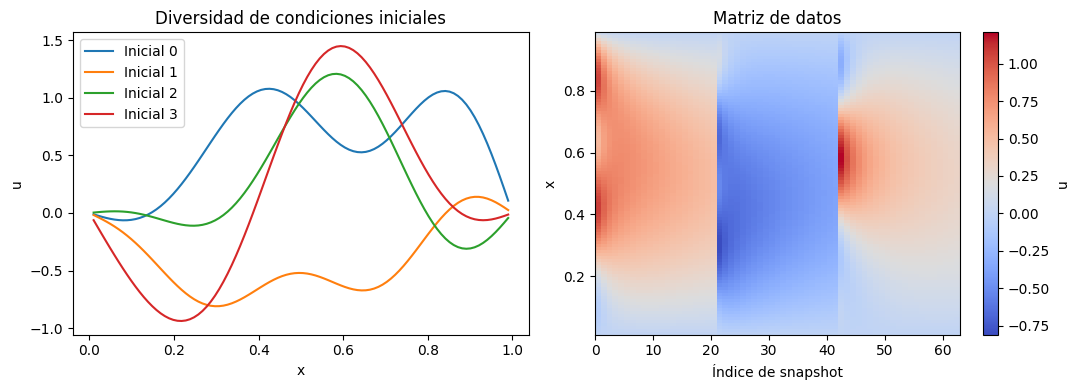

In [2]:
coef_train = rng.normal(size=(24, q))/modos
S = np.concatenate([solucion_continua(c, tiempos) for c in coef_train], axis=1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for i in range(4): axes[0].plot(x, S[:, i*21], label=f'Inicial {i}')
im = axes[1].imshow(S[:, :63], origin='lower', aspect='auto',
                     extent=[0, 63, x[0], x[-1]], cmap='coolwarm')
fig.colorbar(im, ax=axes[1], label='u')
axes[0].set(xlabel='x', ylabel='u', title='Diversidad de condiciones iniciales')
axes[0].legend(); axes[1].set(xlabel='Índice de snapshot', ylabel='x', title='Matriz de datos')
plt.tight_layout(); plt.show()
print('Snapshots:', S.shape)

## 3. POD y la norma física

POD busca una base que minimiza el error cuadrático promedio de proyección de los snapshots. En una malla uniforme aproximamos

$$\langle u,v\rangle_{L^2}\approx h\,\mathbf u^T\mathbf v.$$

La matriz del producto interno es $M=hI$. Aplicamos SVD a $M^{1/2}S=\sqrt hS=U\Sigma V^T$ y construimos

$$\Phi=M^{-1/2}U_r=U_r/\sqrt h,\qquad \Phi^TM\Phi=I_r.$$

Los coeficientes de proyección son $\mathbf a=\Phi^TM\mathbf u$. Esta fórmula evita confundir ortogonalidad euclídea y ortogonalidad física. En elementos finitos, $M$ sería la matriz de masa y no necesariamente una constante por identidad.

En nuestros cinco modos seno, una base suficientemente grande recupera su subespacio. La POD no tiene por qué devolver los senos en orden: combina patrones según la covarianza del dataset.

Rango para 99.5% de energía de entrenamiento: 4
Error de ortogonalidad ponderada: 1.465038760525112e-15


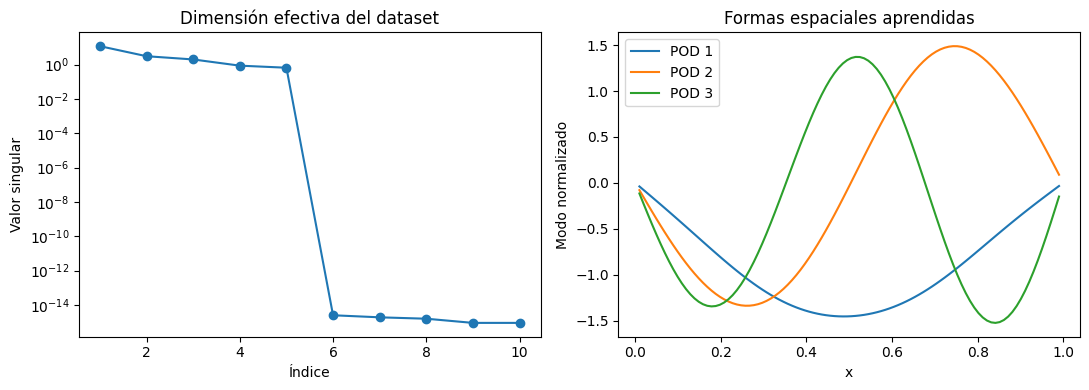

In [3]:
U, singular, Vh = svd(np.sqrt(h)*S, full_matrices=False)
energia = np.cumsum(singular**2)/np.sum(singular**2)
r_995 = int(np.searchsorted(energia, 0.995)+1)
Phi = U[:, :q]/np.sqrt(h)
print('Rango para 99.5% de energía de entrenamiento:', r_995)
print('Error de ortogonalidad ponderada:', np.linalg.norm(h*Phi.T@Phi-np.eye(q)))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogy(np.arange(1, 11), singular[:10], 'o-')
axes[0].set(xlabel='Índice', ylabel='Valor singular', title='Dimensión efectiva del dataset')
for j in range(3): axes[1].plot(x, Phi[:, j], label=f'POD {j+1}')
axes[1].set(xlabel='x', ylabel='Modo normalizado', title='Formas espaciales aprendidas')
axes[1].legend(); plt.tight_layout(); plt.show()

## 4. Energía retenida y error de reconstrucción

La SVD proporciona una propiedad óptima para este dataset y norma:

$$\|M^{1/2}(S-\Phi_r\Phi_r^TMS)\|_F^2
=\sum_{j>r}\sigma_j^2.$$

Retener 99.5 % de energía significa conservar esa fracción de la **norma cuadrática ponderada de los snapshots**. La energía descartada determina el error cuadrático agregado de proyección. No garantiza menos del 0.5 % de error relativo por trayectoria ni preservación de variables de interés pequeñas. El error de norma correspondiente al agregado es la raíz cuadrada de la energía descartada.

Usaremos una condición inicial nueva para medir la reconstrucción y comprobar si lo observado en entrenamiento se mantiene. Esa condición no participó en la SVD.

Error test con cinco modos: 7.995904237029263e-16


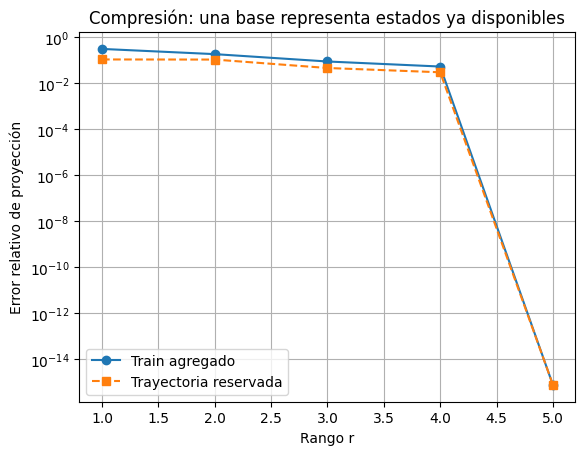

In [4]:
coef_nuevo = rng.normal(size=q)/modos
S_test = solucion_continua(coef_nuevo, tiempos)
errores_train, errores_test = [], []
for r in range(1, q+1):
    P = Phi[:, :r]
    rec_train = P@(h*P.T@S)
    rec_test = P@(h*P.T@S_test)
    errores_train.append(np.linalg.norm(S-rec_train)/np.linalg.norm(S))
    errores_test.append(np.linalg.norm(S_test-rec_test)/np.linalg.norm(S_test))
plt.semilogy(range(1, q+1), np.maximum(errores_train,1e-16), 'o-', label='Train agregado')
plt.semilogy(range(1, q+1), np.maximum(errores_test,1e-16), 's--', label='Trayectoria reservada')
plt.xlabel('Rango r'); plt.ylabel('Error relativo de proyección')
plt.title('Compresión: una base representa estados ya disponibles')
plt.legend(); plt.grid(); plt.show()
print('Error test con cinco modos:', errores_test[-1])

## 5. Galerkin: predecir coeficientes sin conocer el estado futuro

Comprimir snapshots conocidos no equivale a simular una trayectoria nueva. Sustituimos $\mathbf u\approx\Phi\mathbf a$ en el sistema y exigimos que el residuo sea ortogonal a la base:

$$\Phi^TM(\Phi\dot{\mathbf a}-A\Phi\mathbf a)=0.$$

Como $\Phi^TM\Phi=I$, obtenemos

$$\boxed{\dot{\mathbf a}=A_r\mathbf a,\quad A_r=\Phi^TMA\Phi,
\quad\mathbf a(0)=\Phi^TM\mathbf u_0.}$$

El coste de construir $A_r$ se paga en la fase offline. En la fase online resolvemos un sistema de tamaño $r$. La reconstrucción $\Phi\mathbf a$ vuelve a costar $O(nr)$ si necesitamos todos los puntos; para una sola salida puede proyectarse también el observable.

Como $A$ es simétrica negativa definida y $M=hI$, $A_r$ conserva esa estructura. Sus autovalores negativos producen decaimiento. Otros sistemas, bases o proyecciones no garantizan estabilidad automáticamente.

Autovalores de Ar5: [-24.62431684 -15.7710064   -8.87620027  -3.94656873  -0.98688087]
ROM5 vs modelo discreto: 2.7980837429975804e-14


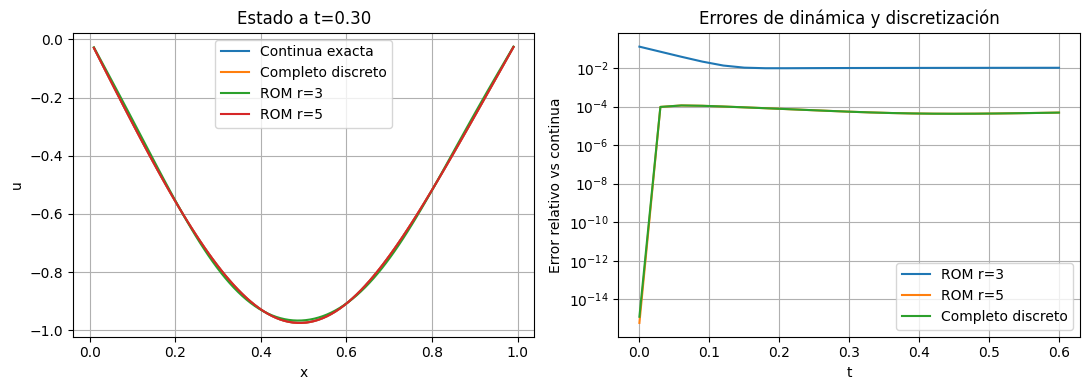

In [5]:
def simular_rom(u0, r, ts):
    P = Phi[:, :r]
    Ar = h*P.T@A@P
    a0 = h*P.T@u0
    coef = np.column_stack([expm(Ar*t)@a0 for t in ts])
    return P@coef, Ar

u0 = solucion_continua(coef_nuevo, [0]).ravel()
pred3, Ar3 = simular_rom(u0, 3, tiempos)
pred5, Ar5 = simular_rom(u0, 5, tiempos)
lam, Q = eigh(A)
full_discreto = Q@(np.exp(lam[:,None]*tiempos[None,:])*(Q.T@u0)[:,None])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
idx = 10
for y, label in [(S_test[:,idx], 'Continua exacta'), (full_discreto[:,idx], 'Completo discreto'),
                  (pred3[:,idx], 'ROM r=3'), (pred5[:,idx], 'ROM r=5')]:
    axes[0].plot(x, y, label=label)
for pred, label in [(pred3,'ROM r=3'), (pred5,'ROM r=5'), (full_discreto,'Completo discreto')]:
    err = np.linalg.norm(pred-S_test, axis=0)/np.linalg.norm(S_test, axis=0)
    axes[1].semilogy(tiempos, np.maximum(err,1e-16), label=label)
axes[0].set(xlabel='x', ylabel='u', title=f'Estado a t={tiempos[idx]:.2f}')
axes[1].set(xlabel='t', ylabel='Error relativo vs continua', title='Errores de dinámica y discretización')
for ax in axes: ax.legend(); ax.grid()
plt.tight_layout(); plt.show()
print('Autovalores de Ar5:', np.linalg.eigvalsh(Ar5))
print('ROM5 vs modelo discreto:', np.linalg.norm(pred5-full_discreto)/np.linalg.norm(full_discreto))
assert np.linalg.norm(pred5-full_discreto)/np.linalg.norm(full_discreto) < 1e-8

## 6. Separar fuentes de error

El ROM con cinco modos coincide con el modelo discreto porque ambos evolucionan dentro del subespacio de los cinco senos. Su pequeña diferencia respecto a la solución continua proviene de aproximar $u_{xx}$ mediante diferencias finitas. Aumentar el rango más allá del subespacio no corregiría ese error espacial.

El ROM de tres modos añade error de truncamiento y modifica la trayectoria. Los modos rápidos decaen, pero sus efectos tempranos y ciertas combinaciones pueden seguir siendo importantes. Para comparar dos ROM, fija la malla del modelo completo y su referencia; para estudiar discretización, refina la malla manteniendo clara esa distinción.

## 7. Una entrada fuera del subespacio aprendido

La base solo contiene los cinco primeros modos. Una condición inicial $\sin(9\pi x)$ es ortogonal a ellos. Su proyección será casi cero y el ROM no representará su transitorio, aunque la energía retenida del entrenamiento sea del 100 %.

Este fallo no es de optimización: los grados de libertad necesarios no existen en la base. La solución puede ser enriquecer snapshots, añadir modos conocidos o construir bases locales para regímenes distintos. Una métrica de entrenamiento elevada no sustituye cobertura física del uso previsto.

Norma de proyección inicial: 2.1719607353853265e-16


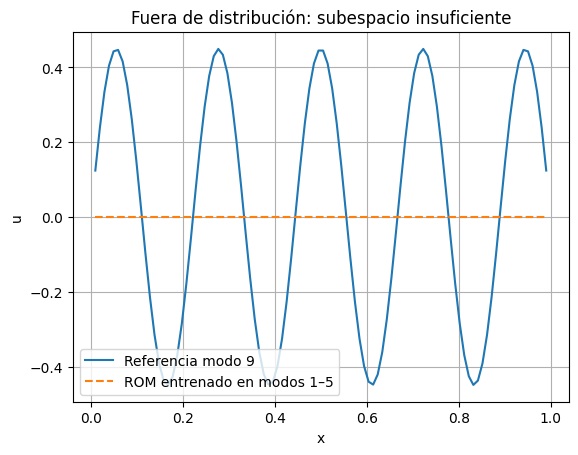

In [6]:
u0_fuera = np.sin(9*np.pi*x)
ts_fuera = np.linspace(0, 0.08, 41)
pred_fuera, _ = simular_rom(u0_fuera, 5, ts_fuera)
ref_fuera = u0_fuera[:,None]*np.exp(-alpha*(9*np.pi)**2*ts_fuera)[None,:]
plt.plot(x, ref_fuera[:,5], label='Referencia modo 9')
plt.plot(x, pred_fuera[:,5], '--', label='ROM entrenado en modos 1–5')
plt.xlabel('x'); plt.ylabel('u'); plt.title('Fuera de distribución: subespacio insuficiente')
plt.legend(); plt.grid(); plt.show()
print('Norma de proyección inicial:', np.sqrt(h)*np.linalg.norm(Phi@(h*Phi.T@u0_fuera)))

## 8. DMD: aprender una evolución lineal de snapshots

Si no conocemos $A$ pero tenemos snapshots a intervalos iguales $\Delta t$, podemos buscar $K$ tal que $X_2\approx KX_1$, donde $X_1=[u_0,\ldots,u_{m-1}]$ y $X_2=[u_1,\ldots,u_m]$.

Una versión reducida de DMD utiliza $X_1=U_r\Sigma_rV_r^T$ y

$$\widetilde K=U_r^TX_2V_r\Sigma_r^{-1}.$$

Sus autovalores describen multiplicadores por paso. Una tasa continua puede obtenerse con $\log\mu/\Delta t$, teniendo cuidado con ramas complejas y aliasing temporal. No deben confundirse autovalores de $K$ y de $A$.

Usamos datos exactos del sistema reducido de cinco modos para ilustrar la identificación. Son datos generados por una dinámica lineal y sin ruido, un caso favorable. En datos ruidosos, el rango y valores singulares pequeños afectan mucho la estimación.

Error máximo de multiplicadores: 4.3298697960381105e-14


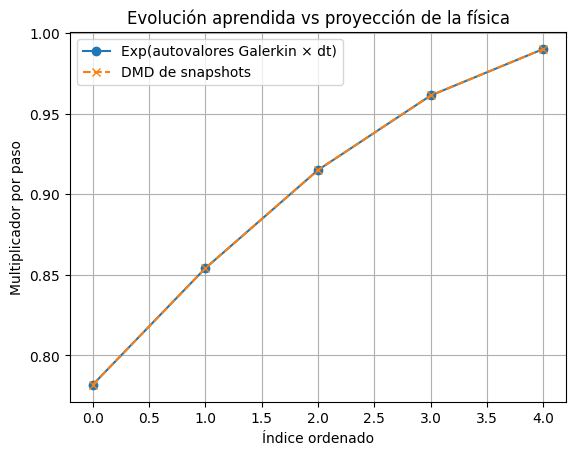

In [7]:
dt = 0.01
ts_dmd = dt*np.arange(41)
datos_dmd, Ar = simular_rom(senos@np.array([1.0,0.8,0.5,0.3,0.2]), 5, ts_dmd)
X1, X2 = np.sqrt(h)*datos_dmd[:, :-1], np.sqrt(h)*datos_dmd[:, 1:]
Ud, sd, Vhd = svd(X1, full_matrices=False)
rd = 5
Ktilde = Ud[:,:rd].T@X2@Vhd[:rd,:].T@np.diag(1/sd[:rd])
mu_dmd = np.sort(np.linalg.eigvals(Ktilde).real)
mu_ref = np.sort(np.exp(np.linalg.eigvalsh(Ar)*dt))
plt.plot(mu_ref, 'o-', label='Exp(autovalores Galerkin × dt)')
plt.plot(mu_dmd, 'x--', label='DMD de snapshots')
plt.xlabel('Índice ordenado'); plt.ylabel('Multiplicador por paso')
plt.title('Evolución aprendida vs proyección de la física')
plt.legend(); plt.grid(); plt.show()
print('Error máximo de multiplicadores:', np.max(np.abs(mu_dmd-mu_ref)))
assert np.max(np.abs(mu_dmd-mu_ref)) < 1e-6

## 9. ROM, autoencoders y operadores neuronales

POD usa un decoder lineal $\mathbf u=\Phi\mathbf a$ y un encoder por proyección. Un autoencoder puede aprender un mapa no lineal entre estado y coordenadas latentes. Esa flexibilidad puede ayudar si los estados viven cerca de una variedad curva, pero reconstrucción precisa no garantiza una dinámica latente estable ni identificable.

Un operador neuronal aprende una transformación entre funciones. Un ROM suele separar representación de estados y evolución de coeficientes. Pueden combinarse: una red predice coeficientes POD desde parámetros, o aprende un término de cierre de la dinámica reducida. El modelo híbrido debe verificarse tanto en espacio físico como en el espacio reducido.

En ecuaciones no lineales, evaluar $\Phi^TMf(\Phi a)$ puede seguir costando $O(n)$. Técnicas de hiperreducción aproximan ese coste usando puntos o bases adicionales. Reducir el número de coeficientes no garantiza por sí solo una aceleración de cada evaluación.

## 10. Fase offline, fase online y salidas relevantes

La fase offline incluye generar snapshots, construir POD, elegir rango y formar operadores. La online incluye proyectar entradas, integrar y obtener observables. Un estudio de rendimiento debe incluir la cantidad de consultas que amortiza el coste inicial, junto con una tolerancia de error común.

Si interesa solo $J(u)=c^Tu$, podemos calcular $J\approx(c^T\Phi)a$ sin reconstruir todos los puntos. Si interesa un máximo local, una base óptima en $L^2$ puede no preservar bien ese máximo. El observable científico debe orientar la validación.

No medimos aceleración con estos 100 puntos: el problema es deliberadamente pequeño y los costes de Python pueden dominar. La reducción estructural de 100 a 5 variables sí puede comprobarse directamente en las matrices.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../15_SCIENTIFIC_MACHINE_LEARNING/15_3_Neural_Operators.ipynb) | [⏩](../15_SCIENTIFIC_MACHINE_LEARNING/15_5_Neural_ODEs.ipynb) |